# 04 · Fenómeno 2 (obligatorio): ¿de dónde sale la "receta"?

Dentro de un mismo producto, ¿las consignas cambian entre rollos y qué explica el
cambio? Verifica la pista de la guía, mide el determinismo de la consigna respecto a la
especificación y busca candidatos a cuasi-experimento. Figuras 3 y 4.

In [1]:
import sys
sys.path.insert(0, "..")  # para importar src/

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.poblacion import preparar, poblacion
from src.estadistica import fraccion_determinada, r2_grupo
from src.visualizacion import estilo, guardar, AZUL, NARANJA, VERDE, GRIS

df, d = preparar()
p = poblacion(df)
estilo()
CONSIGNA = "Temp Enrollado Obj"

## 1. Verificación de la pista de la guía: celdas producto × espesor con varias consignas

In [3]:
celdas = p.groupby(["norma_grado", "rango_espesor"], observed=True)
resumen = celdas.agg(n=("Material Salida", "size"), consignas=(CONSIGNA, "nunique"))
grandes = resumen[resumen["n"] >= 200]
print(f"Celdas producto × rango de espesor con ≥200 rollos: {len(grandes)}")
print(grandes["consignas"].value_counts().sort_index().to_string())
print(f"→ con 2 o 3 consignas: {grandes['consignas'].isin([2, 3]).sum()} (la guía decía ≥29)")

Celdas producto × rango de espesor con ≥200 rollos: 67
consignas
1    35
2    24
3     6
4     1
5     1
→ con 2 o 3 consignas: 30 (la guía decía ≥29)


## 2. ¿Quién fija la consigna? PRAM y la escalera de determinismo (fig. 3)


% de rollos cuya consigna es única dentro de su PRAM: 100.0 %



% de rollos con consigna de enrollado ÚNICA dentro del grupo:
  Producto (Norma | Grado): 30.8 %
  + espesor objetivo: 84.4 %
  + cliente: 92.7 %
  Orden (pedido): 99.3 %


/Users/macbookpro/Desktop/ternium/outputs/figuras/fig3_consigna_especificacion.png


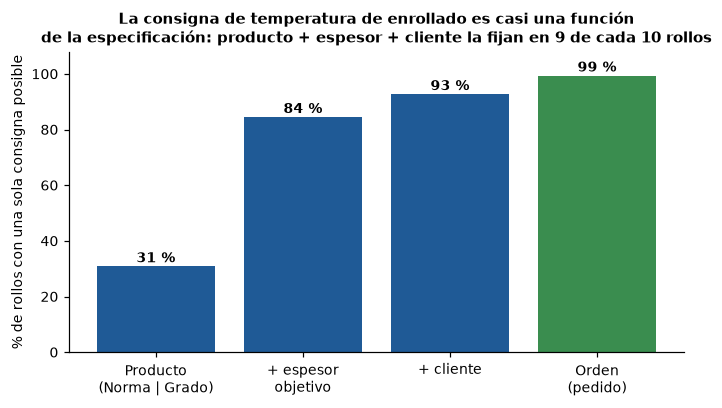

In [4]:
print(f"\n% de rollos cuya consigna es única dentro de su PRAM: "
      f"{fraccion_determinada(p, CONSIGNA, ['PRAM']):.1f} %")
escalera = {
    "Producto\n(Norma | Grado)": ["norma_grado"],
    "+ espesor\nobjetivo": ["norma_grado", "Espesor Objetivo"],
    "+ cliente": ["norma_grado", "Espesor Objetivo", "Cliente"],
    "Orden\n(pedido)": ["Orden"],
}
vals = {k: fraccion_determinada(p, CONSIGNA, cl) for k, cl in escalera.items()}
print("\n% de rollos con consigna de enrollado ÚNICA dentro del grupo:")
for k, v in vals.items():
    print(f"  {k.replace(chr(10), ' ')}: {v:.1f} %")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.bar(list(vals), list(vals.values()), color=[AZUL, AZUL, AZUL, VERDE])
for i, v in enumerate(vals.values()):
    ax.text(i, v + 1.5, f"{v:.0f} %", ha="center", fontsize=9, weight="bold")
ax.set_ylim(0, 108)
ax.set_ylabel("% de rollos con una sola consigna posible")
ax.set_title("La consigna de temperatura de enrollado es casi una función\n"
             "de la especificación: producto + espesor + cliente la fijan en 9 de cada 10 rollos")
print(guardar(fig, "fig3_consigna_especificacion"))

## 3. Dentro de producto: ¿qué explica el cambio de consigna?

In [5]:
prods = [g for g, s in p.groupby("norma_grado", observed=True)
         if len(s) >= 100 and s[CONSIGNA].nunique() >= 2]
r2 = pd.DataFrame({
    "rango de espesor": [r2_grupo(p[p["norma_grado"] == g], CONSIGNA, ["rango_espesor"]) for g in prods],
    "cliente": [r2_grupo(p[p["norma_grado"] == g], CONSIGNA, ["Cliente"]) for g in prods],
    "mes": [r2_grupo(p[p["norma_grado"] == g], CONSIGNA, ["mes"]) for g in prods],
}, index=prods)
print(f"\nR² mediano de la consigna dentro de producto ({len(prods)} productos con ≥100 rollos y ≥2 consignas):")
print(r2.median().round(2).to_string())


R² mediano de la consigna dentro de producto (47 productos con ≥100 rollos y ≥2 consignas):
rango de espesor    0.43
cliente             0.33
mes                 0.21


## 4. Candidatos a cuasi-experimento: cambio de consigna con especificación fija (fig. 4)


Combinaciones producto × espesor × cliente con ≥50 rollos y DOS consignas: 13
  en bloque temporal (1 solo cambio): 3 | intercaladas: 10
/Users/macbookpro/Desktop/ternium/outputs/figuras/fig4_cuasi_experimentos.png


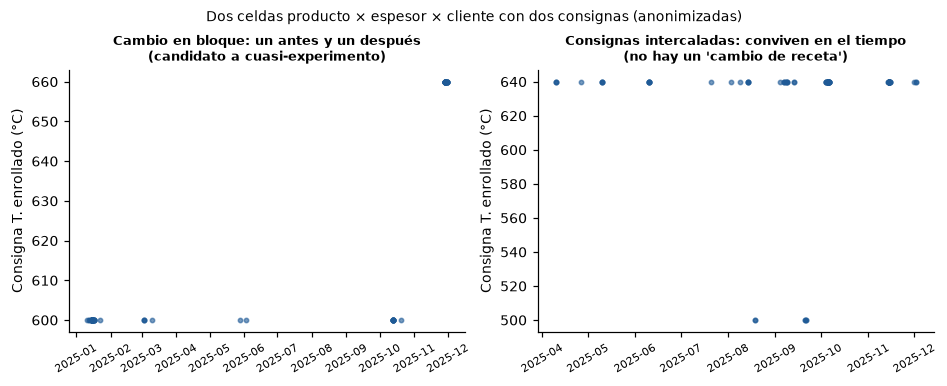

In [6]:
cand = []
for (prod, esp, cli), s in p.groupby(["norma_grado", "Espesor Objetivo", "Cliente"], observed=True):
    if len(s) < 50 or s[CONSIGNA].nunique() != 2:
        continue
    s = s.sort_values("Fecha Inicio")
    cambios = (s[CONSIGNA] != s[CONSIGNA].shift()).sum() - 1
    balance = s[CONSIGNA].value_counts().min()  # rollos del grupo chico
    cand.append({"producto": prod, "espesor": esp, "cliente": cli, "n": len(s),
                 "consignas": sorted(s[CONSIGNA].dropna().unique()), "cambios": int(cambios),
                 "balance": int(balance)})
cand = pd.DataFrame(cand)
print(f"\nCombinaciones producto × espesor × cliente con ≥50 rollos y DOS consignas: {len(cand)}")
if len(cand):
    print(f"  en bloque temporal (1 solo cambio): {(cand['cambios'] == 1).sum()} | "
          f"intercaladas: {(cand['cambios'] > 1).sum()}")

# Figura 4: una celda en bloque (cuasi-experimento) y una intercalada, anonimizadas
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4), sharey=False)
sel = pd.concat([cand[cand["cambios"] == 1].sort_values("balance").tail(1),
                 cand[cand["cambios"] > 3].sort_values("n").tail(1)])
titulos = ["Cambio en bloque: un antes y un después\n(candidato a cuasi-experimento)",
           "Consignas intercaladas: conviven en el tiempo\n(no hay un 'cambio de receta')"]
for ax, (_, row), titulo in zip(axes, sel.iterrows(), titulos):
    s = p[(p["norma_grado"] == row["producto"]) & (p["Espesor Objetivo"] == row["espesor"]) &
          (p["Cliente"] == row["cliente"])].sort_values("Fecha Inicio")
    ax.scatter(s["Fecha Inicio"], s[CONSIGNA], s=8, color=AZUL, alpha=0.6)
    ax.set_title(titulo, fontsize=8.5)
    ax.set_ylabel("Consigna T. enrollado (°C)")
    ax.tick_params(axis="x", labelsize=7, rotation=30)
fig.suptitle("Dos celdas producto × espesor × cliente con dos consignas (anonimizadas)", fontsize=9)
print(guardar(fig, "fig4_cuasi_experimentos"))

## 5. Seguimiento de la consigna

In [7]:
print(f"\nSeguimiento (real − objetivo) de T. de enrollado en la población: "
      f"mediana {p['dev_te'].median():.1f} °C, p10 {p['dev_te'].quantile(0.1):.1f}, "
      f"p90 {p['dev_te'].quantile(0.9):.1f}")


Seguimiento (real − objetivo) de T. de enrollado en la población: mediana -3.5 °C, p10 -9.1, p90 0.9
